In [5]:
#Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from lmfit.models import GaussianModel, VoigtModel, ConstantModel
from scipy.special import wofz
from scipy.signal import find_peaks
from scipy.ndimage import median_filter
from scipy.interpolate import UnivariateSpline
from pathlib import Path

<h2 style="color: #e19edc;"> Antares</h2>

<h3 style="color: #e19edc;"> Espectros que viene con longitud de onda y flujo</h3>
<h3 style="color: #e19edc;"> 2023</h3>

In [6]:
ruta_24_agosto = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectros de Antares\2023\agosto 24 de 2023.xlsx"
ruta_29_agosto = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectros de Antares\2023\agosto 29 de 2023.xlsx"
ruta_01_septiembre = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectros de Antares\2023\septiembre 1 de 2023.xlsx"
ruta_08_septiembre = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectros de Antares\2023\septiembre 8 de 2023.xlsx"
ruta_12_octubre = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectros de Antares\2023\octubre 12 de 2023.xlsx"
ruta_19_octubre = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectros de Antares\2023\octubre 19 de 2023.xlsx"

In [8]:
antares_24_agosto = pd.read_excel(ruta_24_agosto, sheet_name = "Sheet1", usecols = [1,2],header = None, names = ["Longitud onda", "Flujo"])
antares_29_agosto = pd.read_excel(ruta_29_agosto, sheet_name = "Sheet1", usecols = [1,2],header = None, names = ["Longitud onda", "Flujo"])
antares_01_septiembre = pd.read_excel(ruta_01_septiembre, sheet_name = "Sheet1", usecols = [1,2],header = None, names = ["Longitud onda", "Flujo"])
antares_08_septiembre = pd.read_excel(ruta_08_septiembre, sheet_name = "Sheet1", usecols = [1,2],header = None, names = ["Longitud onda", "Flujo"])
antares_12_octubre = pd.read_excel(ruta_12_octubre, sheet_name = "Sheet1", usecols = [1,2],header = None, names = ["Longitud onda", "Flujo"])
antares_19_octubre = pd.read_excel(ruta_19_octubre, sheet_name = "Sheet1", usecols = [1,2],header = None, names = ["Longitud onda", "Flujo"])

<h4 style="color: #e19edc;"> Parámetros de la normalización con el método Sigma - Clipping</h4>
<h5 style="color: #e19edc;"> Normalización de espectros</h5>

In [9]:
espectros_por_normalizar = {
    "antares_24_agosto": antares_24_agosto,
    "antares_29_agosto": antares_29_agosto,
    "antares_01_septiembre": antares_01_septiembre,
    "antares_08_septiembre": antares_08_septiembre,
    "antares_12_octubre": antares_12_octubre,
    "antares_19_octubre": antares_19_octubre,
}

In [10]:
guardar_graficos = True   
carpeta_graficos = "./Graficas 2023/Espectros_normalizados"  
 
col_longitud_onda = "Longitud onda"
col_flujo = "Flujo"
 
grado_polinomio= 2     
N_iteraciones = 10
sigma_corte = 2.0

In [11]:
def ajustar_continuo(longitud_onda, flujo, grado, n_iter, sigma):

    longitud_onda = np.asarray(longitud_onda, dtype=float)
    flujo = np.asarray(flujo, dtype=float)
 
    mascara = np.ones_like(flujo, dtype=bool)
 
    for _ in range(n_iter):
        coef = np.polyfit(longitud_onda[mascara], flujo[mascara], deg=grado)
        continuo_iter = np.polyval(coef, longitud_onda)
 
        residuo = flujo - continuo_iter
        
        mediana = np.median(residuo[mascara])
        mad = np.median(np.abs(residuo[mascara] - mediana))
        mad_std = mad * 1.4826

        umbral_superior = mediana + sigma * mad_std
        umbral_inferior = mediana - sigma * mad_std
        nueva_mascara = (residuo > umbral_inferior) & (residuo < umbral_superior)
 
        if nueva_mascara.sum() < grado + 2:
            break

        if np.array_equal(nueva_mascara, mascara):
            break
 
        mascara = nueva_mascara
 
    coef_final = np.polyfit(longitud_onda[mascara], flujo[mascara], deg=grado)
    continuo = np.polyval(coef_final, longitud_onda)
 
    return continuo, mascara


Procesando: antares_24_agosto
  Puntos totales: 180
  Puntos excluidos: 44
  -> Gráfico guardado: Graficas 2023\Espectros_normalizados\antares_24_agosto_control.png


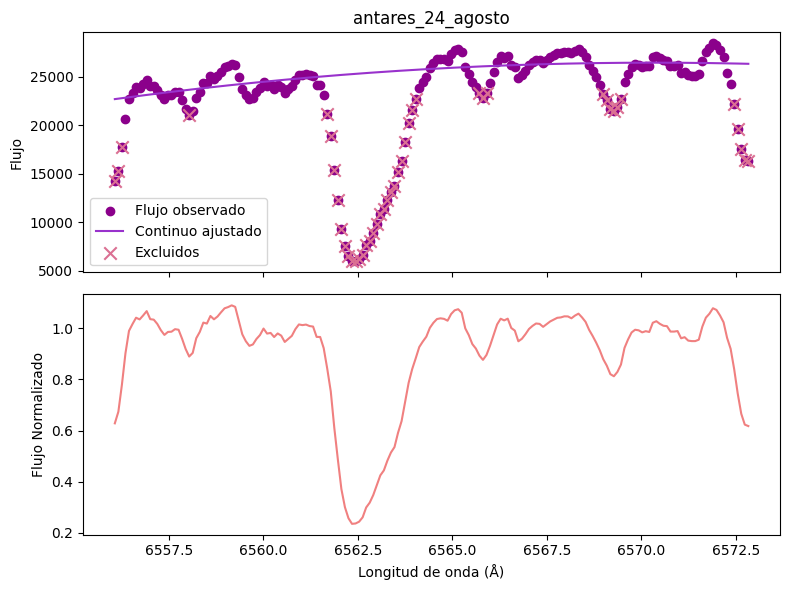


Procesando: antares_29_agosto
  Puntos totales: 180
  Puntos excluidos: 55
  -> Gráfico guardado: Graficas 2023\Espectros_normalizados\antares_29_agosto_control.png


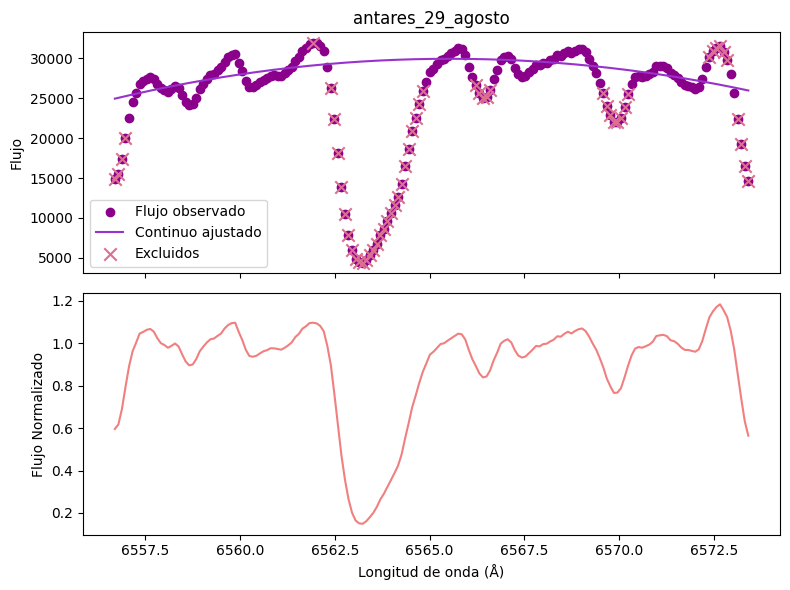


Procesando: antares_01_septiembre
  Puntos totales: 180
  Puntos excluidos: 58
  -> Gráfico guardado: Graficas 2023\Espectros_normalizados\antares_01_septiembre_control.png


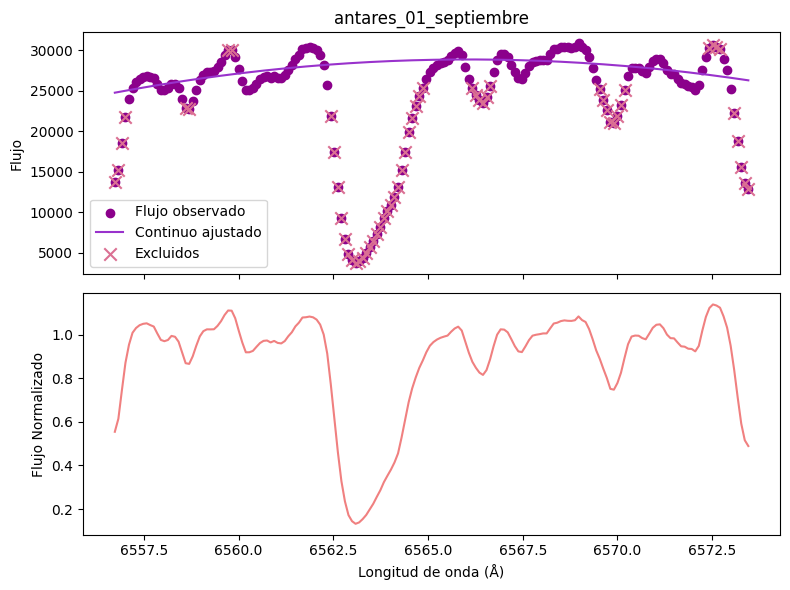


Procesando: antares_08_septiembre
  Puntos totales: 180
  Puntos excluidos: 53
  -> Gráfico guardado: Graficas 2023\Espectros_normalizados\antares_08_septiembre_control.png


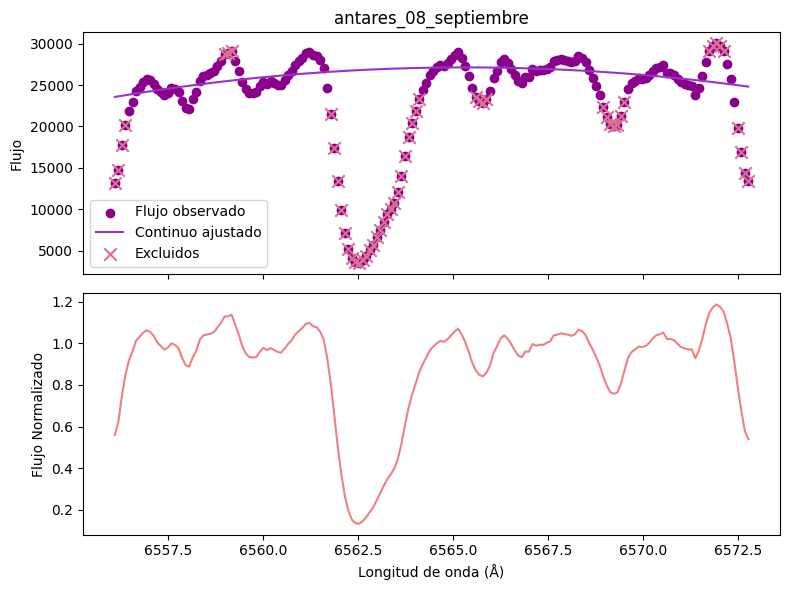


Procesando: antares_12_octubre
  Puntos totales: 180
  Puntos excluidos: 72
  -> Gráfico guardado: Graficas 2023\Espectros_normalizados\antares_12_octubre_control.png


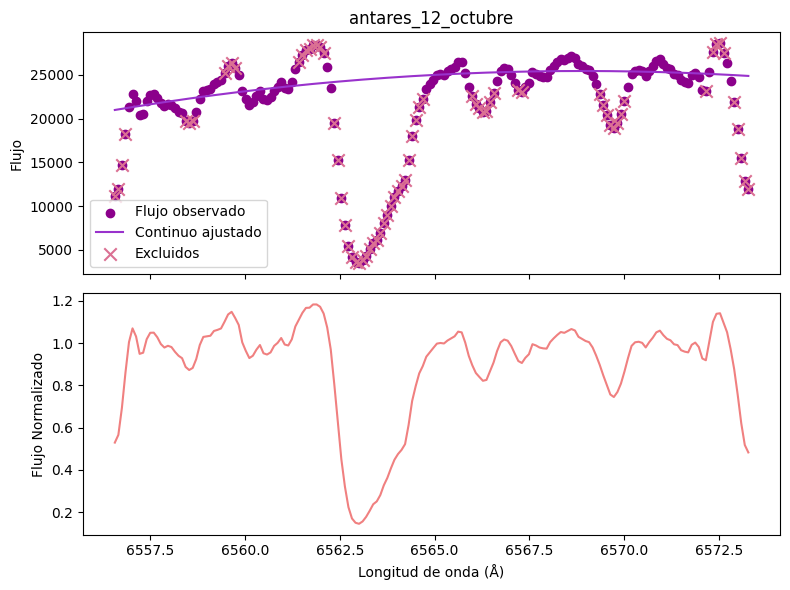


Procesando: antares_19_octubre
  Puntos totales: 180
  Puntos excluidos: 88
  -> Gráfico guardado: Graficas 2023\Espectros_normalizados\antares_19_octubre_control.png


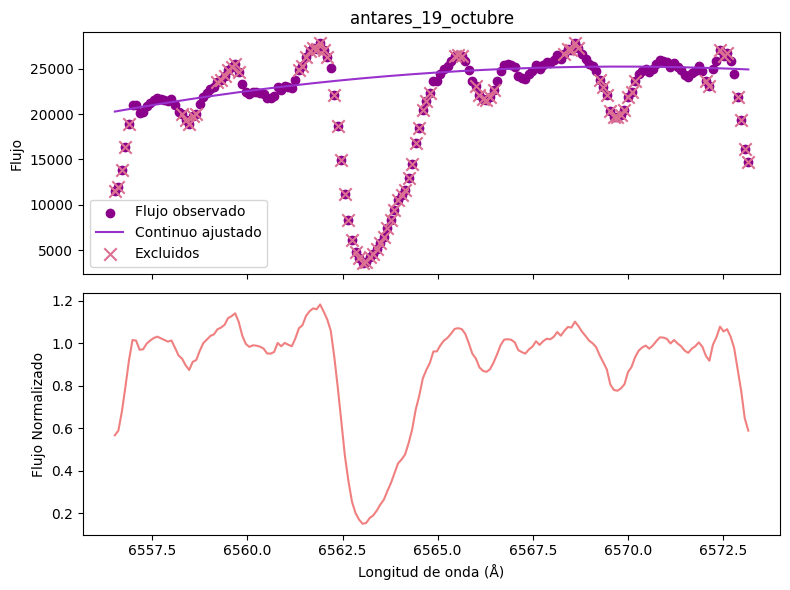


Proceso completo.


In [12]:
if guardar_graficos:
    Path(carpeta_graficos).mkdir(exist_ok=True)
 
for nombre, df in espectros_por_normalizar.items():
    print(f"\nProcesando: {nombre}")
 
    longitud_onda = df[col_longitud_onda].values
    flujo = df[col_flujo].values
 
    continuo, mascara_continuo = ajustar_continuo(longitud_onda, flujo, grado_polinomio, N_iteraciones, sigma_corte)

    df["Continuo ajustado"] = continuo
    df["Flujo Normalizado"] = flujo / continuo
    df["Usado en ajuste"] = mascara_continuo

    print(f"  Puntos totales: {len(mascara_continuo)}")
    print(f"  Puntos excluidos: {(~mascara_continuo).sum()}")

    mascara_bool = np.asarray(mascara_continuo, dtype=bool)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
 
    ax1.scatter(longitud_onda, flujo, color = "darkmagenta", label="Flujo observado")
    ax1.plot(longitud_onda, continuo, color ="darkorchid", label="Continuo ajustado")
    ax1.scatter(longitud_onda[~mascara_bool], flujo[~mascara_bool], color = "palevioletred",marker = "x", label="Excluidos", s = 80)
    ax1.set_ylabel("Flujo")
    ax1.legend()
    ax1.set_title(nombre)
 
    ax2.plot(longitud_onda, df["Flujo Normalizado"], color ="lightcoral")
    ax2.set_ylabel("Flujo Normalizado")
    ax2.set_xlabel("Longitud de onda (Å)")
 
    plt.tight_layout()
 
    if guardar_graficos:
        fig_path = Path(carpeta_graficos) / f"{nombre}_control.png"
        plt.savefig(fig_path, dpi=120)
        print(f"  -> Gráfico guardado: {fig_path}")
 
    plt.show()
    plt.close(fig)
 
print("\nProceso completo.")

<h3 style="color: #e19edc;"> Obtención del perfil de absorción y emisión de la línea H<sub>&alpha;</sub></h3>
<h4 style="color: #e19edc;"> Teniendo en cuenta las posibles mezclas con las líneas de absorción</h4>
<h5 style="color: #e19edc;"> Datos </h5>

In [112]:
# Datos completos
archivos = [
    {
        "fecha": "Agosto 24-2023",
        "datos": antares_24_agosto,
        "ventana_vecinos": 3,
        "centro_aprox": 6562.346,
        "velocidad_metalica": 0,  # km/s
        "incertidumbre_v": 3.0,
        "buscar_velocidad": True,
        "semillas": range(-12, 13, 3),
        "velocidad_telurica": -29.154, #km/s,
        "marco": "Estrella",
    },
    {
        "fecha": "Agosto 29-2023",
        "datos": antares_29_agosto,
        "ventana_vecinos": 2,
        "centro_aprox": 6563.234,
        "velocidad_metalica": 28,  # km/s
        "incertidumbre_v": 0.5,
        "velocidad_telurica": -29.381, #km/s
        "buscar_velocidad": True,
        "marco": "Tierra",
    },
    {
        "fecha": "Septiembre 01-2023",
        "datos": antares_01_septiembre,
        "ventana_vecinos":3,
        "centro_aprox": 6563.088,
        "velocidad_metalica": 29.19,  # km/s
        "incertidumbre_v": 0.2,
        "velocidad_telurica": -29.61, #km/s
        "marco": "Tierra",
    },
    {
        "fecha": "Septiembre 08-2023",
        "datos": antares_08_septiembre,
        "ventana_vecinos":3,
        "centro_aprox": 6562.528,
        "velocidad_metalica": 0.0,  # km/s
        "incertidumbre_v": 3.0,
        "velocidad_telurica": -29.504, #km/s
        "marco": "Estrella",
    },
    {
        "fecha": "Octubre 12-2023",
        "datos": antares_12_octubre,
        "ventana_vecinos":1,
        "centro_aprox": 6563.099,
        "velocidad_metalica": 22.73,  # km/s
        "incertidumbre_v": 0.28,
        "velocidad_telurica": -23.047, #km/s
        "marco": "Tierra",
    },
    {
        "fecha": "Octubre 19-2023",
        "datos": antares_19_octubre,
        "ventana_vecinos":2,
        "centro_aprox": 6563.028,
        "velocidad_metalica": 22.42,  # km/s
        "incertidumbre_v": 0.4,
        "velocidad_telurica": -20.607, #km/s
        "marco": "Tierra"
    },
]

<h5 style="color: #e19edc;"> Funciones Auxiliares</h5>

In [113]:
c_kms_s = 299792.458

def efecto_doppler(longitud_lab, velocidad_kms):
    return longitud_lab * (1 + velocidad_kms / c_kms_s)


def profundidad_interpolada(teff, t_ref=(3500, 4250), prof_ref=(0.55, 0.63)):
    return float(np.interp(teff, t_ref, prof_ref))


def pico_unitario_voigt(sigma, gamma):
    z = 1j * gamma / (sigma * np.sqrt(2))
    return wofz(z).real / (sigma * np.sqrt(2 * np.pi))

In [114]:
def estimar_continuo_por_planitud(longitud_onda, flujo, rango_flujo,max_variacion=0.015, ventana_vecinos=2,
                                    grado_ajuste=1, min_puntos=5):

    serie_flujo = pd.Series(flujo)

    ventana_total = 2 * ventana_vecinos + 1
    variacion_local = serie_flujo.rolling(window=ventana_total, center=True).std()

    mascara_rango = (flujo >= rango_flujo[0]) & (flujo <= rango_flujo[1])
    mascara_plano = (variacion_local < max_variacion).to_numpy()

    mascara = mascara_rango & mascara_plano

    x_sel = longitud_onda[mascara]
    y_sel = flujo[mascara]

    if x_sel.size < min_puntos:
        raise ValueError(
            f"Solo se encontraron {x_sel.size} puntos de continuo (mínimo {min_puntos}). "
            f"Ajustá 'rango_flujo' o 'max_variacion'. Rango de flujo real en este espectro: "
            f"[{flujo.min():.3f}, {flujo.max():.3f}]"
        )

    orden = np.argsort(x_sel)
    x_sel, y_sel = x_sel[orden], y_sel[orden]

    coef = np.polyfit(x_sel, y_sel, deg=grado_ajuste)
    continuo_func = np.poly1d(coef)

    return continuo_func, x_sel, y_sel

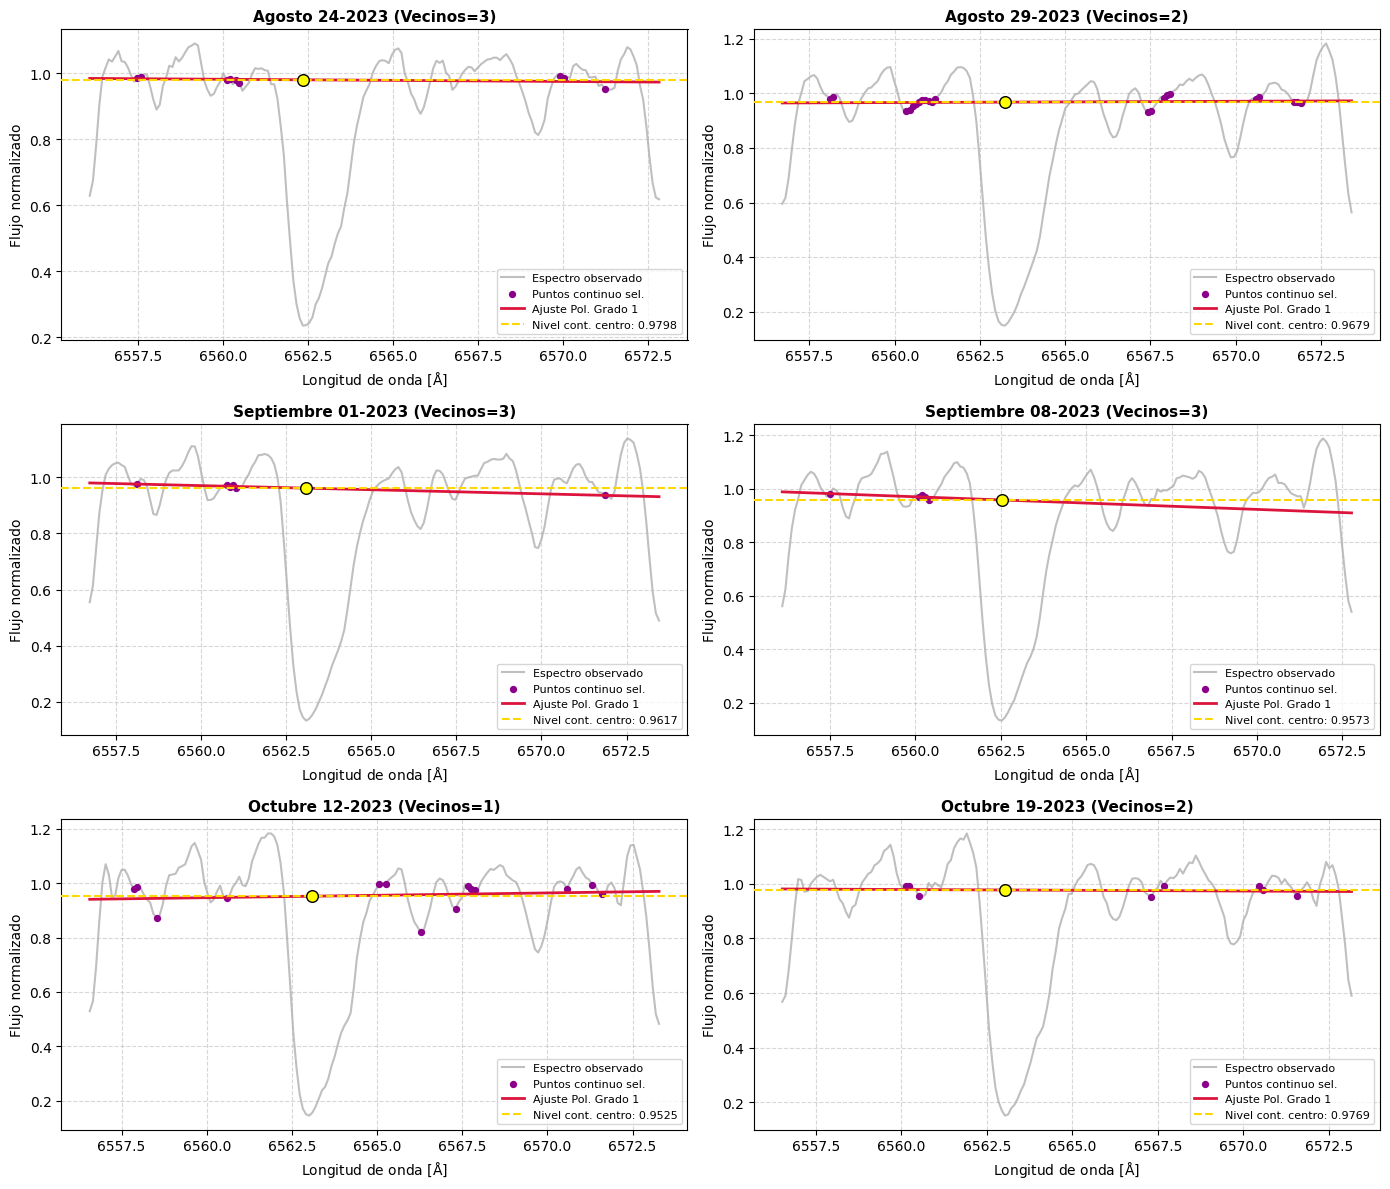

,Espectro / Fecha,Vecinos (G1),Continuo Centro (G1),Residuo std (G1)
0,Agosto 24-2023,3,0.9798,0.01051
1,Agosto 29-2023,2,0.9679,0.01818
2,Septiembre 01-2023,3,0.9617,0.00364
3,Septiembre 08-2023,3,0.9573,0.00568
4,Octubre 12-2023,1,0.9525,0.05055
5,Octubre 19-2023,2,0.9769,0.01715


In [115]:
# Configuración manual de vecinos por prueba específica
vecinos_manuales = {
    "Agosto 24-2023": {"v_g1": 3},
    "Agosto 29-2023": {"v_g1": 2},
    "Septiembre 01-2023": {"v_g1": 3},
    "Septiembre 08-2023": {"v_g1": 3},
    "Octubre 12-2023": {"v_g1": 1},
    "Octubre 19-2023": {"v_g1": 2},
}

filas_comparativa = []

n_columnas = 2
max_filas = 4
tam_bloque = n_columnas * max_filas

n_bloques = int(np.ceil(len(archivos) / tam_bloque))

for bloque_idx in range(n_bloques):

    bloque = archivos[bloque_idx * tam_bloque: (bloque_idx + 1) * tam_bloque]
    n_graficas = len(bloque)
    n_filas_bloque = int(np.ceil(n_graficas / n_columnas))

    fig, axes = plt.subplots(
        n_filas_bloque,
        n_columnas,
        figsize=(14, 4 * n_filas_bloque)
    )

    axes = np.array(axes).flatten()

    for i, archivo in enumerate(bloque):

        fecha = archivo["fecha"]
        df = archivo["datos"]
        centro_aprox = archivo["centro_aprox"]

        longitud_onda = df["Longitud onda"].values
        flujo = df["Flujo Normalizado"].values

        # Extraer ventana manual

        cfg = vecinos_manuales.get(fecha, {"v_g1": 2})
        v_g1 = cfg["v_g1"]

        # Grado 1

        try:

            cont_func1, x_sel1, y_sel1 = estimar_continuo_por_planitud(longitud_onda, flujo,
                rango_flujo=(0.8, 1), max_variacion=0.015, ventana_vecinos=v_g1, grado_ajuste=1)

            res1 = y_sel1 - cont_func1(x_sel1)

            c_centro1 = round(float(cont_func1(centro_aprox)), 4)

            std1 = round(float(np.std(res1)), 5)

        except Exception as e:

            cont_func1 = None
            c_centro1, std1 = None, f"Falló: {e}"

        # Tabla de resultados

        filas_comparativa.append({
            "Espectro / Fecha": fecha,
            "Vecinos (G1)": v_g1,
            "Continuo Centro (G1)": c_centro1,
            "Residuo std (G1)": std1
        })

        # Selección de Subplot con base en el índice

        ax = axes[i]

        ax.plot(longitud_onda, flujo, color="gray", alpha=0.5, label="Espectro observado", zorder=1)

        if cont_func1 is not None:

            # Continuo
            ax.scatter(x_sel1, y_sel1, color="darkmagenta", s=18, label="Puntos continuo sel.", zorder=2)

            # Ajuste polinómico
            ax.plot(longitud_onda, cont_func1(longitud_onda), color="crimson", lw=2, label="Ajuste Pol. Grado 1",
                     zorder=3)

            # Continuo evaluado en Hα
            ax.axhline(c_centro1, color="gold", linestyle="--", lw=1.5,
                       label=f"Nivel cont. centro: {c_centro1:.4f}", zorder=3)

            # Punto del centro aproximado
            ax.scatter([centro_aprox], [c_centro1], color="yellow", edgecolor="black", s=70, zorder=4)

        # Configuración del subplot
        ax.set_title(f"{fecha} (Vecinos={v_g1})", fontsize=11, fontweight="bold")
        ax.set_xlabel(r"Longitud de onda [$\mathrm{\AA}$]")
        ax.set_ylabel("Flujo normalizado")
        ax.legend(fontsize=8, loc="lower right")
        ax.grid(True, linestyle="--", alpha=0.5)

    # Eliminación de subplots vacíos si el número de espectros del bloque es impar

    for j in range(n_graficas, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()

    sufijo = f"_parte{bloque_idx + 1}" if n_bloques > 1 else ""

    plt.savefig(fr"Graficas 2023\Continuo\Continuo_espectros_normalizados_ESPARTACO2{sufijo}.png",
        dpi=300, bbox_inches="tight")

    plt.show()

tabla_comparativa_manual = pd.DataFrame(filas_comparativa)

display(tabla_comparativa_manual)

In [116]:
def estimar_ancho_inicial_metalica(longitud_onda, flujo, continuo_local, centro_obs, ventana=0.5, sigma_default=0.12, gamma_default=0.05):

    mask = np.abs(longitud_onda - centro_obs) < ventana
    if mask.sum() < 4:
        return sigma_default, gamma_default

    x_local = longitud_onda[mask]
    y_local = flujo[mask]


    nivel_min = np.percentile(y_local, 2)
    prof_local = continuo_local - nivel_min
    if prof_local <= 0:
        return sigma_default, gamma_default

    nivel_media_altura = continuo_local - prof_local / 2

    por_debajo = y_local < nivel_media_altura
    if por_debajo.sum() < 2:
        return sigma_default, gamma_default

    x_cruce = x_local[por_debajo]
    fwhm_est = x_cruce.max() - x_cruce.min()

    if fwhm_est <= 0:
        return sigma_default, gamma_default

    sigma_inicial = max(0.02, fwhm_est / 2.355)
    gamma_inicial = max(0.0, fwhm_est * 0.15)

    return sigma_inicial, gamma_inicial

Construcción del modelo

In [117]:
#MODELO DE AJUSTE

def construccion_del_modelo(lineas_metalicas=None):
    continuo = ConstantModel(prefix="cont_")
    em_azul = VoigtModel(prefix="em_azul_")
    valle_abs = VoigtModel(prefix="valle_abs_")
    modelo = continuo + em_azul + valle_abs

    if lineas_metalicas:
        for linea in lineas_metalicas:
            modelo += VoigtModel(prefix=f"{linea['nombre']}_")

    return modelo

In [118]:
def encontrar_parametros(modelo, longitud_onda, flujo, centro_aprox, continuo_func=None, x_sel=None, y_sel=None,
                         lineas_metalicas=None, teff=3660,rango_flujo=(0.8, 1.0), max_variacion=0.015, ventana_vecinos=2):
    
    p = modelo.make_params()
    p._asteval.symtable['pico_unitario_voigt'] = pico_unitario_voigt

    # Continuo (Planitud)
    if continuo_func is None or x_sel is None or y_sel is None:
        continuo_func, x_sel, y_sel = estimar_continuo_por_planitud(
            longitud_onda, flujo, rango_flujo=rango_flujo, 
            max_variacion=max_variacion, ventana_vecinos=ventana_vecinos, grado_ajuste=1
        )

    # Continuo en el centro de la línea (aproximado)
    continuo_local = float(continuo_func(centro_aprox))
    
    # Dispersión (ruido) respecto al ajuste polinomial
    residuos_continuo = y_sel - continuo_func(x_sel)
    disp_continuo = float(np.std(residuos_continuo))

    # Definición de márgenes y parámetro en lmfit
    margen = max(0.05, 4 * disp_continuo)
    p["cont_c"].set(value=continuo_local, min=continuo_local - margen, max=continuo_local + margen)


    # Emisión Azul
    flujo_suave = median_filter(flujo, size=5)
    izquierda = (longitud_onda < (centro_aprox - 0.2)) & (longitud_onda > (centro_aprox - 2.5))

    if np.any(izquierda):
        x_izq = longitud_onda[izquierda]
        y_izq = flujo_suave[izquierda]
        picos, props = find_peaks(y_izq, prominence=0.01)

        if len(picos) > 0:
            idx_mejor = picos[np.argmax(props["prominences"])]
            c_azul_inicio = x_izq[idx_mejor]
            amp_azul_inicio = max(0.05, flujo[izquierda][idx_mejor] - continuo_local)
        else:
            i_azul = np.argmax(y_izq)
            c_azul_inicio = x_izq[i_azul]
            amp_azul_inicio = max(0.05, flujo[izquierda][i_azul] - continuo_local)
    else:
        c_azul_inicio = centro_aprox - 0.8
        amp_azul_inicio = 0.2

    p["em_azul_center"].set(value = c_azul_inicio, min = c_azul_inicio - 0.3, max = c_azul_inicio + 0.3)
    p["em_azul_amplitude"].set(value=amp_azul_inicio * 0.5, min=0, max=amp_azul_inicio * 5.0)
    p["em_azul_sigma"].set(value = 0.20, min = 0.05, max = 0.5)
    p["em_azul_gamma"].set(value = 0.10, min = 0.0, max = 0.3, vary=True)

    # Absorción Central
    
    ventana_centro = np.abs(longitud_onda - centro_aprox) < 1.8
    if np.any(ventana_centro):
        idx_local = np.argmin(flujo_suave[ventana_centro])
        c_abs_inicio = longitud_onda[ventana_centro][idx_local]
    else:
        c_abs_inicio = centro_aprox

    i_min = np.argmin(np.abs(longitud_onda - c_abs_inicio))

    p["valle_abs_center"].set(value=c_abs_inicio, min=centro_aprox - 1.0, max=centro_aprox + 1.0)

    prof_abs_est = max(0.1, continuo_local - flujo[i_min])
    amp_abs_inicio = -prof_abs_est * 0.8
    p["valle_abs_amplitude"].set(value=amp_abs_inicio, min=-5.0, max=0)
    p["valle_abs_sigma"].set(value=0.25, min=0.05, max=1.0)
    p["valle_abs_gamma"].set(value=0.15, min=0, max=0.8, vary=True)

    # Líneas Metálicas
    
    if lineas_metalicas:
        for linea in lineas_metalicas:
            pref = f"{linea['nombre']}_"
            c0_lab = linea["centro"]

            v = linea.get("velocidad", 28.0)
            c0_obs = efecto_doppler(c0_lab, v)
            margen_v = max(linea.get("incertidumbre_v", 3.0), 0.5)
            margen_aa = c0_lab * margen_v / c_kms_s
            p[f"{pref}center"].set(value=c0_obs, min=c0_obs - margen_aa, max=c0_obs + margen_aa)

            # Estimación del ancho inicial
            sigma0_dato, gamma0_dato = estimar_ancho_inicial_metalica(longitud_onda, flujo, continuo_local, c0_obs)

            sigma0 = linea.get("sigma_inicial", sigma0_dato)
            gamma0 = linea.get("gamma_inicial", gamma0_dato)

            sigma_margen = 0.05
            gamma_margen = 0.05
            p[f"{pref}sigma"].set(value=sigma0, min=max(0.02, sigma0 - sigma_margen), max=min(0.4, sigma0 + sigma_margen))
            p[f"{pref}gamma"].set(value=gamma0, min=max(0.0, gamma0 - gamma_margen), max=min(0.3, gamma0 + gamma_margen), vary=True)

            prof = linea.get("profundidad")
            if prof is None:
                prof = profundidad_interpolada(teff, t_ref=linea.get("t_ref", (3500, 4250)), prof_ref=linea.get("prof_ref", (0.55, 0.63)))

            p[f"{pref}amplitude"].set(expr=f"-{prof} * cont_c / pico_unitario_voigt({pref}sigma, {pref}gamma)")

    return p, continuo_func

In [119]:
# DESCOMPOSICIÓN DE "PERFILES"

def fit_y_decomposicion(datos_cercanos, centro_aprox, col_longitud="Longitud onda", 
                        col_flujo="Flujo Normalizado", continuo_func=None, 
                        x_sel=None, y_sel=None, lineas_metalicas=None, teff=3660, ventana_vecinos = 2):
    
    # Extraemos los datos numéricos de la ventana recortada
    longitud_onda = datos_cercanos[col_longitud].to_numpy()
    flujo = datos_cercanos[col_flujo].to_numpy()

    # Construimos el modelo con lmfit
    modelo = construccion_del_modelo(lineas_metalicas)
    
    # Contiuo local
    parametros, cont_func_usado = encontrar_parametros(
        modelo, longitud_onda, flujo, centro_aprox,
        continuo_func=continuo_func, x_sel=x_sel, y_sel=y_sel,
        lineas_metalicas=lineas_metalicas, teff=teff, ventana_vecinos = ventana_vecinos)
    
    # Ajuste
    fit = modelo.fit(flujo, parametros, x=longitud_onda, nan_policy='omit')

    # Evaluación de componentes
    comps = fit.eval_components(x=longitud_onda)
    continuo = comps["cont_"]

    perfil_emision = continuo + comps.get("em_azul_", 0)
    perfil_absorcion = continuo + comps.get("valle_abs_", 0)
    residuo = flujo - fit.best_fit

    return dict(
        longitud_onda=longitud_onda, flujo=flujo, fit=fit, comps=comps, 
        perfil_emision=perfil_emision, perfil_absorcion=perfil_absorcion, 
        residuo=residuo, continuo_func=cont_func_usado)

In [120]:
def ajuste_multisemilla(df, centro_aprox, linea_base, semillas=range(20, 30, 2), margen=2.0, teff=3660, ventana_vecinos=2):
    
    #Prueba diferentes velocidades y toma la que tiene menor chi^2
    
    mejor, tabla = None, []
    for v_s in semillas:
        lin = [{**linea_base, "velocidad": v_s, "incertidumbre_v": margen}]
        try:
            r = fit_y_decomposicion(df, centro_aprox, "Longitud onda", "Flujo Normalizado",
                                    lineas_metalicas=lin, teff=teff, ventana_vecinos=ventana_vecinos)
        except Exception as e:
            print(f"  semilla {v_s}: falló ({e})")
            continue
        c_co = r["fit"].params["Cobalto_center"].value
        v_fit = (c_co - 6563.397) / 6563.397 * c_kms_s
        chi = r["fit"].redchi
        tabla.append((v_s, round(v_fit, 2), round(chi, 4)))
        if mejor is None or chi < mejor[0]:
            mejor = (chi, v_fit, r, lin)
    print("  semilla | v_fit | chi²red")
    for fila in tabla:
        print("  ", fila)
    return mejor[2], mejor[3], mejor[1]   # Resultado, Líneas usadas, V_fit

In [121]:
# VISUALIZACIÓN

def visualizacion_con_metalica(res_metal, lineas_metalicas, mes, titulo, rango_x = None):
    longitud_onda, flujo, fit = res_metal["longitud_onda"], res_metal["flujo"], res_metal["fit"]
    comps = res_metal["comps"]
    continuo = comps["cont_"]

    fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True,
                              gridspec_kw={"height_ratios": [2.2, 1]})

    ax = axes[0]
    ax.scatter(longitud_onda, flujo, s=18, color="darkcyan", label="Observado", zorder=3)
    ax.plot(longitud_onda, fit.best_fit, color="lightseagreen", lw=1.8, label="Modelo total")
    ax.plot(longitud_onda, res_metal["perfil_emision"], "--", color="turquoise", lw=1.3,
            label="Perfil de emisión")
    ax.plot(longitud_onda, res_metal["perfil_absorcion"], "--", color="deepskyblue", lw=1.3,
            label=r"Perfil de absorción $H_\alpha$")

    for linea in lineas_metalicas:
        pref = f"{linea['nombre']}_"
        perfil_metal = continuo + comps[pref]
        ax.plot(longitud_onda, perfil_metal, "-.", color="purple", lw=1.3,
                label=f"Componente {linea['nombre']}")
        ax.axvline(fit.params[f"{pref}center"].value, color="orchid", lw=2.5, ls=":", alpha=0.7)

    ax.axhline(continuo[0], color="gray", lw=0.7, ls=":")
    ax.set_ylabel("Flujo normalizado")
    ax.set_title(titulo, fontsize=14, fontweight='bold')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

    ax2 = axes[1]
    ax2.plot(longitud_onda, res_metal["residuo"], color="black", lw=1)
    ax2.axhline(0, color="gray", lw=0.7)
    ax2.set_xlabel("Longitud de onda [Å]")
    ax2.set_ylabel("Residuo")
    ax2.grid(alpha=0.3)

    if rango_x is not None:
        ax.set_xlim(rango_x)

    plt.tight_layout()
    plt.savefig(fr"Graficas 2023\Modelamiento\halpha_{mes.lower()}_cobalto.png", dpi=150)
    plt.show()

Agosto 24-2023 → búsqueda multisemilla
  semilla | v_fit | chi²red
   (-12, -10.34, np.float64(0.0069))
   (-9, -10.74, np.float64(0.0069))
   (-6, -9.0, np.float64(0.0069))
   (-3, -6.0, np.float64(0.007))
   (0, -3.0, np.float64(0.0071))
   (3, 0.0, np.float64(0.0073))
   (6, 3.0, np.float64(0.0076))
   (9, 6.0, np.float64(0.0079))
   (12, 9.0, np.float64(0.0083))
  Desfase Co = -10.34 km/s 


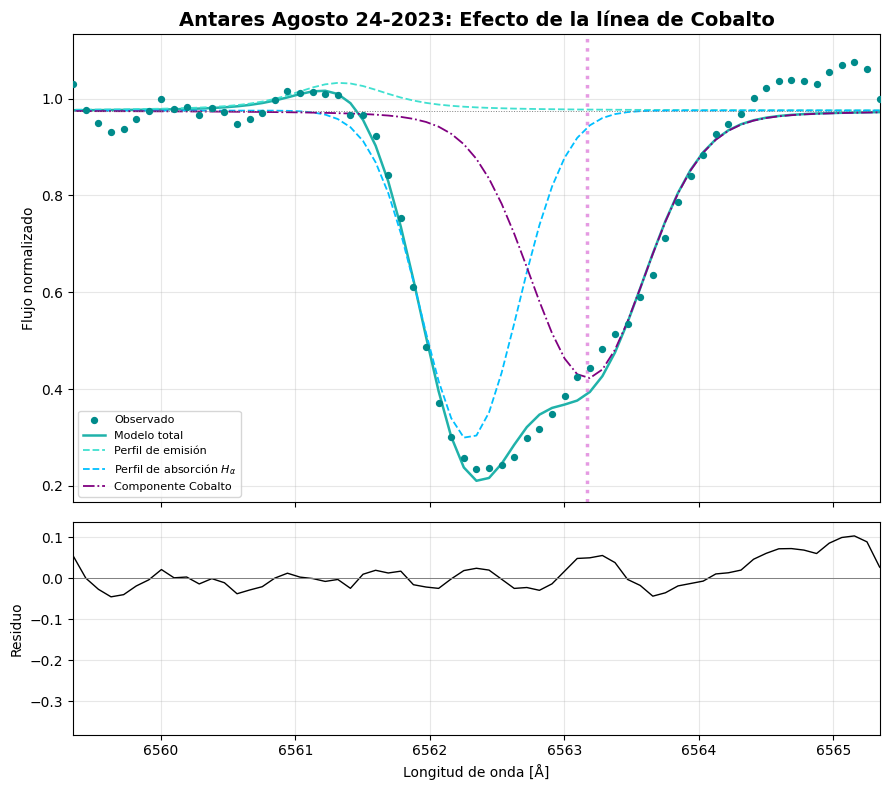

Agosto 29-2023 → búsqueda multisemilla
  semilla | v_fit | chi²red
   (20, 20.5, np.float64(0.0091))
   (22, 22.5, np.float64(0.009))
   (24, 24.5, np.float64(0.0089))
   (26, 26.5, np.float64(0.0089))
   (28, 28.13, np.float64(0.0089))
  Desfase Co = 28.13 km/s 


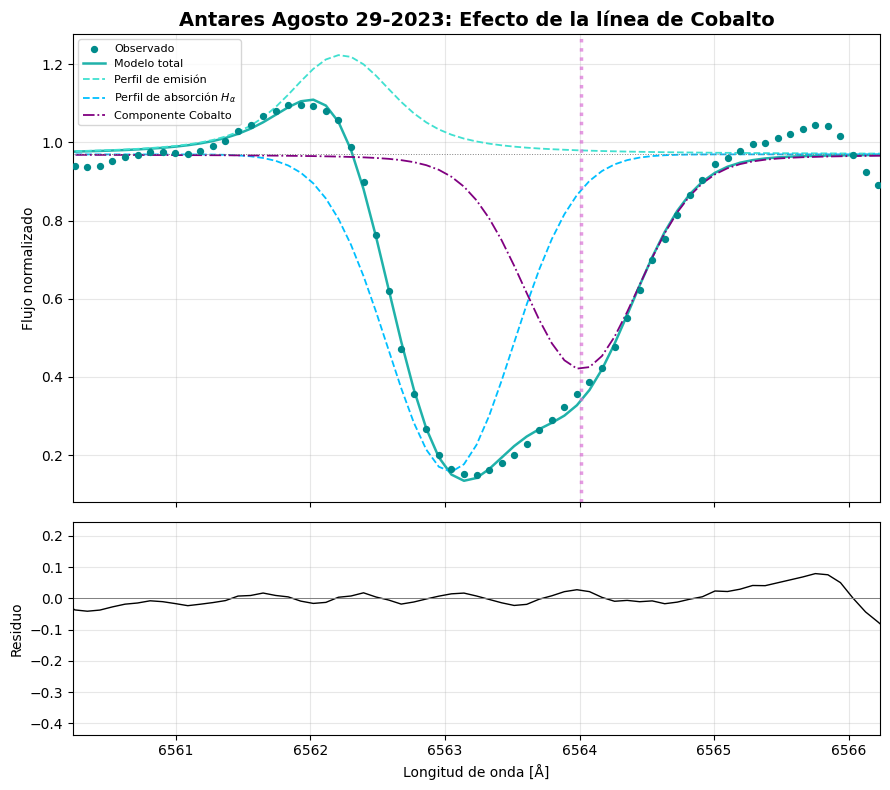

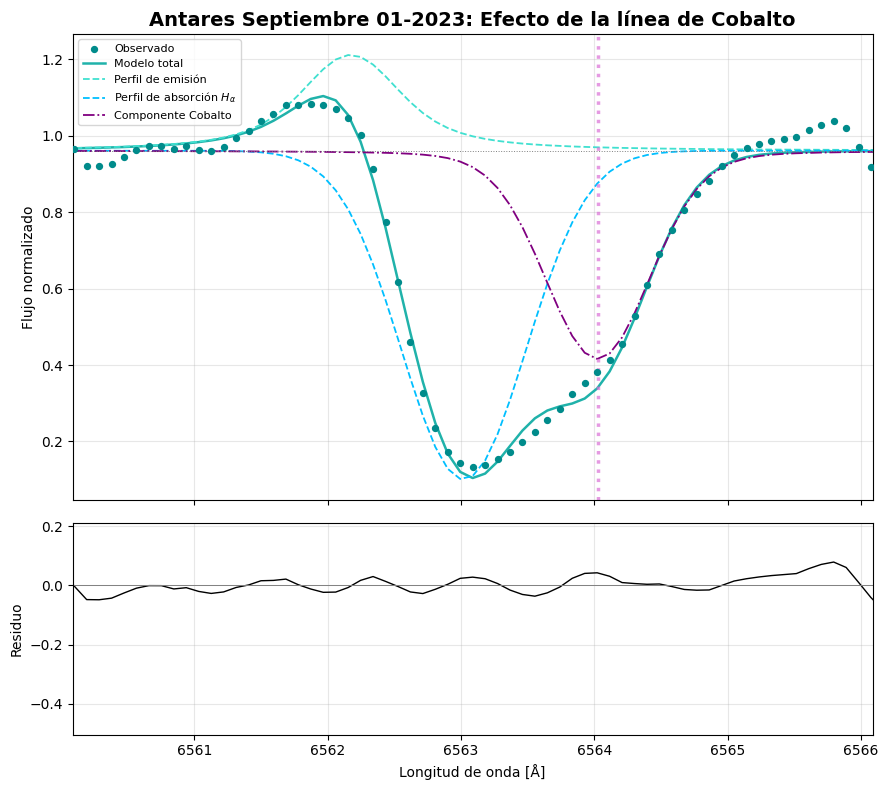

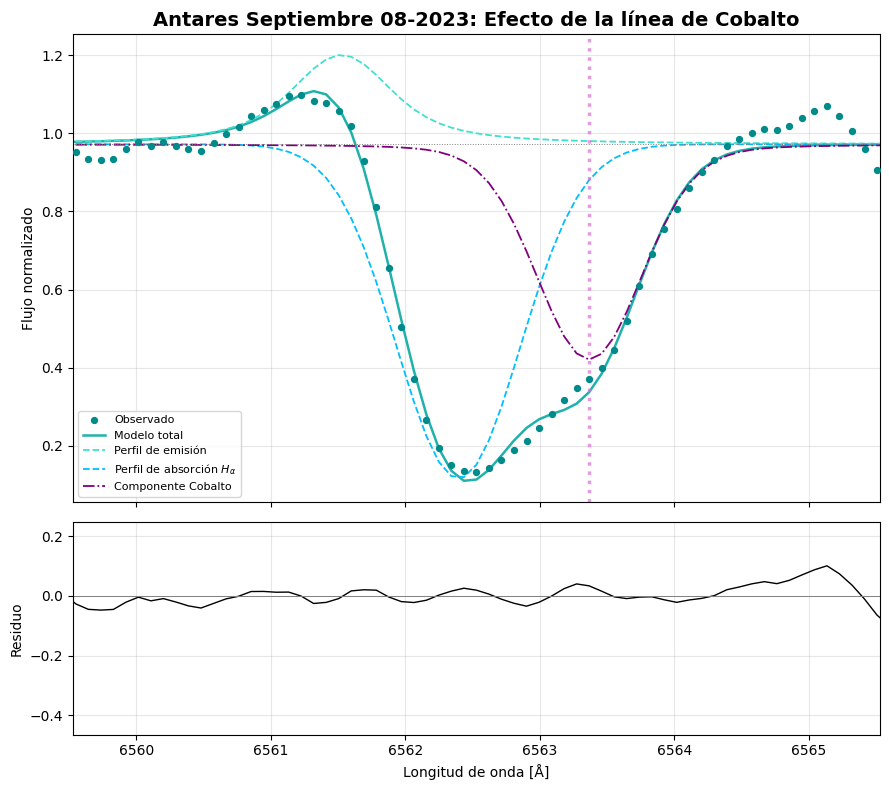

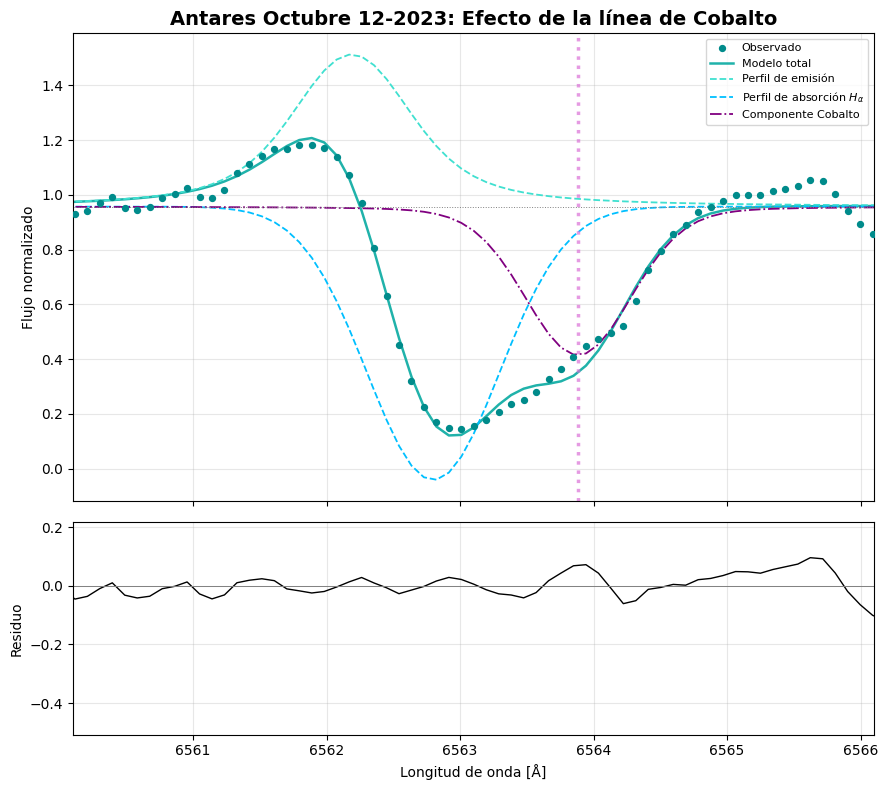

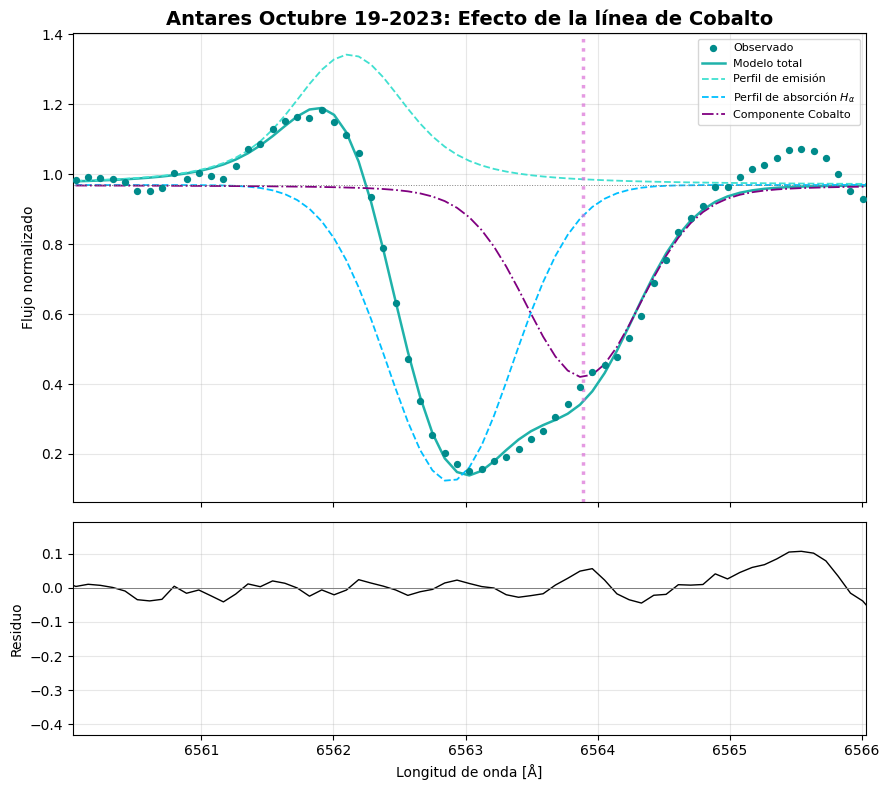

In [122]:
resultados = {}
velocidades_ajustadas = {}

for archivo in archivos:

    fecha = archivo["fecha"]

    lineas_metalicas = [
        {
            "nombre": "Cobalto",
            "centro": 6563.397,
            "ion": "Co I",
            "velocidad": archivo["velocidad_metalica"],
            "incertidumbre_v": archivo["incertidumbre_v"],
            "prof_ref": (0.55, 0.63),
            "t_ref": (3500, 4250),
        }
    ]

    if archivo.get("buscar_velocidad", False):

        # Búsqueda para fechas específicas
        print(fecha, "→ búsqueda multisemilla")

        res, lineas_metalicas, v_fit = ajuste_multisemilla( archivo["datos"], archivo["centro_aprox"], lineas_metalicas[0],
        semillas=archivo.get("semillas", range(20, 30, 2)), margen=archivo["incertidumbre_v"],ventana_vecinos=archivo["ventana_vecinos"])

        velocidades_ajustadas[fecha] = v_fit

        print(f"  Desfase Co = {v_fit:.2f} km/s ")

    else:

        res = fit_y_decomposicion( archivo["datos"], archivo["centro_aprox"], "Longitud onda", "Flujo Normalizado",
            lineas_metalicas=lineas_metalicas, teff=3660, ventana_vecinos=archivo["ventana_vecinos"])

    resultados[fecha] = res

    visualizacion_con_metalica(res, lineas_metalicas, fecha, titulo=f"Antares {fecha}: Efecto de la línea de Cobalto",
        rango_x=(archivo["centro_aprox"] - 3, archivo["centro_aprox"] + 3))

<h3 style="color: #e19edc;"> Obtención de los parámetros del ajuste de H<sub>&alpha;</sub></h3>

In [124]:
marcos = {m["fecha"]: m.get("marco", "Tierra") for m in archivos}

correcciones_velocidades = {
    m["fecha"]: (m.get("velocidad_telurica", np.nan) if m.get("marco", "Tierra") == "Tierra" else np.nan)
    for m in archivos
}

In [125]:
h_alpha_natural = 6562.812  # Å
cobalto_natural = 6563.397  # Å

resultados_perfiles_halpha_y_cobalto = []

for fecha, res in resultados.items():
    v_corr = correcciones_velocidades[fecha]   # NaN si el espectro no está en marco Tierra
    marco = marcos[fecha]
    p = res["fit"].params
    comps = res["comps"]
    longitud_onda = res["longitud_onda"]
    continuo = comps["cont_"]

    # COBALTO (referencia para el marco de velocidades)
    c_co = p["Cobalto_center"].value
    fwhm_co = p["Cobalto_fwhm"].value
    prof_co = abs(p["Cobalto_height"].value)
    z_co = (c_co - cobalto_natural) / cobalto_natural
    v_co = z_co * c_kms_s
    ew_co = np.trapezoid(abs(comps["Cobalto_"]) / continuo, longitud_onda)

    #EMISIÓN AZUL
    c_em = p["em_azul_center"].value
    fwhm_em = p["em_azul_fwhm"].value
    amp_em = p["em_azul_height"].value
    z_em = (c_em - h_alpha_natural) / h_alpha_natural
    v_em = z_em * c_kms_s
    ew_em = np.trapezoid(comps["em_azul_"] / continuo, longitud_onda)

    resultados_perfiles_halpha_y_cobalto.append({
        "Época": fecha,
        "Marco": marco,
        "Componente": "Emisión Azul Hα",
        "Centro [Å]": round(c_em, 3),
        "z": round(z_em, 6),
        "Velocidad en espectro [km/s]": round(v_em, 2),
        "Velocidad heliocéntrica [km/s]": round(v_em + v_corr, 2),
        "Δv respecto a Co [km/s]": round(v_em - v_co, 2),
        "Profundidad / Altura": round(amp_em, 4),
        "FWHM [Å]": round(fwhm_em, 3),
        "EW [Å]": round(ew_em, 4)
    })

    # 2. ABSORCIÓN Hα
    c_abs = p["valle_abs_center"].value
    fwhm_abs = p["valle_abs_fwhm"].value
    prof_abs = abs(p["valle_abs_height"].value)
    z_abs = (c_abs - h_alpha_natural) / h_alpha_natural
    v_abs = z_abs * c_kms_s
    ew_abs = np.trapezoid(abs(comps["valle_abs_"]) / continuo, longitud_onda)

    resultados_perfiles_halpha_y_cobalto.append({
        "Época": fecha,
        "Marco": marco,
        "Componente": "Absorción Hα",
        "Centro [Å]": round(c_abs, 3),
        "z": round(z_abs, 6),
        "Velocidad en espectro [km/s]": round(v_abs, 2),
        "Velocidad heliocéntrica [km/s]": round(v_abs + v_corr, 2),
        "Δv respecto a Co [km/s]": round(v_abs - v_co, 2),
        "Profundidad / Altura": round(prof_abs, 4),
        "FWHM [Å]": round(fwhm_abs, 3),
        "EW [Å]": round(ew_abs, 4)
    })

    # 3. COBALTO
    resultados_perfiles_halpha_y_cobalto.append({
        "Época": fecha,
        "Marco": marco,
        "Componente": "Absorción Cobalto",
        "Centro [Å]": round(c_co, 3),
        "z": round(z_co, 6),
        "Velocidad en espectro [km/s]": round(v_co, 2),
        "Velocidad heliocéntrica [km/s]": round(v_co + v_corr, 2),
        "Δv respecto a Co [km/s]": 0.0,
        "Profundidad / Altura": round(prof_co, 4),
        "FWHM [Å]": round(fwhm_co, 3),
        "EW [Å]": round(ew_co, 4)
    })

tabla_resultados = pd.DataFrame(resultados_perfiles_halpha_y_cobalto)
display(tabla_resultados)

,Época,Marco,Componente,Centro [Å],z,Velocidad en espectro [km/s],Velocidad heliocéntrica [km/s],Δv respecto a Co [km/s],Profundidad / Altura,FWHM [Å],EW [Å]
0,Agosto 24-2023,Estrella,Emisión Azul Hα,6561.334,-0.000225,-67.49,NaN,-57.15,0.0572,0.852,0.0686
1,Agosto 24-2023,Estrella,Absorción Hα,6562.290,-0.000079,-23.83,NaN,-13.49,0.6794,0.850,0.6299
2,Agosto 24-2023,Estrella,Absorción Cobalto,6563.171,-0.000035,-10.34,NaN,0.00,0.5532,1.026,0.6541
3,Agosto 29-2023,Tierra,Emisión Azul Hα,6562.228,-0.000089,-26.69,-56.07,-54.82,0.2542,0.935,0.3288
4,Agosto 29-2023,Tierra,Absorción Hα,6563.038,0.000034,10.32,-19.06,-17.81,0.8124,1.095,0.9766
5,Agosto 29-2023,Tierra,Absorción Cobalto,6564.013,0.000094,28.13,-1.25,0.00,0.5497,1.026,0.6535
6,Septiembre 01-2023,Tierra,Emisión Azul Hα,6562.174,-0.000097,-29.16,-58.77,-57.85,0.2506,0.904,0.3189
7,Septiembre 01-2023,Tierra,Absorción Hα,6563.021,0.000032,9.54,-20.07,-19.15,0.8598,1.099,1.0472
8,Septiembre 01-2023,Tierra,Absorción Cobalto,6564.025,0.000096,28.69,-0.92,0.00,0.5447,0.933,0.5917
9,Septiembre 08-2023,Estrella,Emisión Azul Hα,6561.525,-0.000196,-58.77,NaN,-57.41,0.2286,0.896,0.2855


In [126]:
tabla_resultados.to_excel(fr"Parámetros para análisis de Antares\resultados perfiles halpha 2023.xlsx", index=False)